In [14]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar
import gc

In [15]:
def find_box_corners(plon, plat, lon_edge, lat_edge):
    lat_min, lat_max = plat - lat_edge / 2, plat + lat_edge / 2
    lon_min, lon_max = plon - lon_edge / 2, plon + lon_edge / 2

    # Correct longitude boundaries
    while lon_min < -180:
        lon_min += 360
    while lon_max > 180:
        lon_max -= 360
    
    if lon_max % 1.5 == 0:
        lon_max -= 0.0001
    if lat_max % 1.5 == 0:
        lat_max -= 0.0001

    return lat_min, lat_max, lon_min, lon_max

In [16]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [17]:
def define_mask(lat_min,lat_max,
               lon_min,lon_max):
    
    lat_res, lon_res = 1.5, 1.5
    lats = np.arange(0, 91, lat_res)
    lons = np.arange(-180, 180, lon_res)
    
    mask = ((lats[:, None] >= lat_min) & (lats[:, None] <= lat_max) &
            (lons >= lon_min) & (lons <= lon_max))
    
    mask_xr = xr.DataArray(mask.astype(int), coords=[lats, lons], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1
    
    return mask_bool

In [18]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

persistences_list = []

box_edges=[[40,70,-180,180],
           [40,70,-180,180], 
           [40,70,75,160], 
           [40,70,75,160]]

ds_length = 36000  # Number of days to consider for each experiment

# Load datasets
ds_clims = []
ds_composites = []
compute_climatology = False

if compute_climatology:
    for i,experiment in enumerate(experiments):
        print(experiment)

        #import needed fields
        chunk_size = 30  # e.g., 30 days per chunk
        
        ds = xr.open_dataset(
            f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
            chunks={'time': chunk_size}
        ).isel(time=slice(0, ds_length))        
        print('ds imported')
        LWAA_arr = ds['LWAA_tracked']
        print(LWAA_arr.shape)
        #in the second half of the dataset you need to change the sign of qgpv.
        time_length = LWAA_arr.shape[0]
        #qgpv_field = xr.concat([ds['dw_qgpv'][:int(time_length/2)], -ds['dw_qgpv'][int(time_length/2):]], dim='time')
        qgpv_field = ds['dw_qgpv'].load()
        mean_qgpv_field = qgpv_field.mean('time')
        print(qgpv_field.shape)
        ds_temp = flip_and_append(
            xr.open_mfdataset(
                f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
                combine='by_coords',
                parallel=True,
                chunks={'time': chunk_size}  # chunk size of one month (approximate)
            )
        ).isel(time=slice(0, ds_length))
        t850 = ds_temp['temp'][:,3,:,:].load()
        mean_t850 = t850.mean('time')
        print(t850.shape)

        FC = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-11.nc')['FC']

        #import the tracking dictionary
        dic = np.load(f'{base_path}/{experiment}/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)
        
        #compute blocking climatology

        block_freq = ds['LWAA_freq'].rename('block_freq')
        block_freq_std = (LWAA_arr.std('time')/np.sqrt(365*50)*100).rename('block_freq_std')

        #define the dimensions of the composite domain
    
        lon_edge = 72
        lat_edge = 42

        shape = [int(lat_edge/1.5), int(lon_edge/1.5)]
        
        #initialize composites:
        
        composite_qgpv = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv'
        )     

        composite_qgpv_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv_ano'
        )

        composite_t850_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_t850_ano'
        )

        counter = 0

        mask_bool = define_mask(box_edges[i][0],box_edges[i][1],box_edges[i][2],box_edges[i][3])
        inspected_labels = []
        persistences = []
        '''
        #METHOD 1
        for t in tqdm(range(LWAA_arr.shape[0])):
            #print(LWAA_arr.shape)
            #print(mask_bool.shape)
            if np.any(LWAA_arr.values[t,mask_bool]>0):
                try:
                    labels = np.unique(LWAA_arr.values[t,mask_bool])[1:]
                    #we take into account only one blocking event per day
                    blocking_onset_relative_day = t-dic[labels[0]]['time']
                    if labels[0] not in inspected_labels:
                        inspected_labels.append(labels[0])
                        persistences.append(dic[labels[0]]['persistence'])
                    center_of_mass = [dic[labels[0]]['track'][0][blocking_onset_relative_day],dic[labels[0]]['track'][1][blocking_onset_relative_day]]
                    box = find_box_corners(center_of_mass[1],center_of_mass[0],lon_edge,lat_edge)
                    #take into consideration when the box crosses the 180° lon
                    if box[2] > box[3]:
                        # Box crosses the 180° boundary
                        sel1 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_mean = mean_qgpv_field.loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850 = t850[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850_mean = mean_t850.loc[box[0]:box[1], slice(box[2], 180)]
                        
                        sel2 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_mean = mean_qgpv_field.loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850 = t850[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850_mean = mean_t850.loc[box[0]:box[1], slice(-180, box[3])]
                        
                        selected_qgpv = xr.concat([sel1, sel2], dim='lon').values
                        selected_qgpv_mean = xr.concat([sel1_mean, sel2_mean], dim='lon').values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        seleceted_t850_mean = xr.concat([sel1_t850_mean, sel2_t850_mean], dim='lon').values
                        selected_t850_anomaly = xr.concat([sel1_t850, sel2_t850], dim='lon').values - seleceted_t850_mean
                        
                    else:
                        
                        selected_qgpv = qgpv_field[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values
                        selected_qgpv_mean = mean_qgpv_field.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        selected_t850_mean = mean_t850.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_t850_anomaly = t850[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values - selected_t850_mean
                    
                    composite_qgpv += selected_qgpv
                    composite_qgpv_ano += selected_anomaly
                    composite_t850_ano += selected_t850_anomaly
                
                    counter += 1
                except:
                    print('non critical error')
            '''
        #METHOD 2
        for event in tqdm(dic[1:]):
            time = event['time']
            if time + event['persistence'] > ds_length:
                break
            center_of_mass_lon = event['track'][1]
            center_of_mass_lat = event['track'][0]
            for j in range(len(center_of_mass_lon)):
                #print(center_of_mass_lat[j])
                if center_of_mass_lat[j] > box_edges[i][0] and center_of_mass_lat[j] < box_edges[i][1] and\
                   center_of_mass_lon[j] > box_edges[i][2] and center_of_mass_lon[j] < box_edges[i][3]:
                    t = time + j
                    box = find_box_corners(center_of_mass_lon[j],center_of_mass_lat[j],lon_edge,lat_edge)
                    #take into consideration when the box crosses the 180° lon
                    if box[2] > box[3]:
                        # Box crosses the 180° boundary
                        sel1 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_mean = mean_qgpv_field.loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850 = t850[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850_mean = mean_t850.loc[box[0]:box[1], slice(box[2], 180)]
                        
                        sel2 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_mean = mean_qgpv_field.loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850 = t850[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850_mean = mean_t850.loc[box[0]:box[1], slice(-180, box[3])]
                        
                        selected_qgpv = xr.concat([sel1, sel2], dim='lon').values
                        selected_qgpv_mean = xr.concat([sel1_mean, sel2_mean], dim='lon').values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        seleceted_t850_mean = xr.concat([sel1_t850_mean, sel2_t850_mean], dim='lon').values
                        selected_t850_anomaly = xr.concat([sel1_t850, sel2_t850], dim='lon').values - seleceted_t850_mean
                        
                    else:
                        
                        selected_qgpv = qgpv_field[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values
                        selected_qgpv_mean = mean_qgpv_field.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        selected_t850_mean = mean_t850.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_t850_anomaly = t850[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values - selected_t850_mean
                    
                    composite_qgpv += selected_qgpv
                    composite_qgpv_ano += selected_anomaly
                    composite_t850_ano += selected_t850_anomaly
                
                    counter += 1


        composite_qgpv /= counter
        composite_qgpv_ano /= counter
        composite_t850_ano /= counter

        #print(composite_qgpv,composite_qgpv_ano,composite_t850)

        ds = xr.merge([block_freq,block_freq_std,FC])
        ds.to_netcdf(f'{base_path}/{experiment}/tot/block_freq_FC_data_tmp.nc')
        ds_clims.append(ds)

        ds2 = xr.merge([composite_qgpv,composite_qgpv_ano,composite_t850_ano])
        ds2.to_netcdf(f'{base_path}/{experiment}/tot/composites_data_tmp.nc')
        ds_composites.append(ds2)

        persistences_list.append(persistences)        

        # After saving datasets
        ds = None
        ds2 = None
        ds_clims.clear()
        ds_composites.clear()
        persistences_list.clear()
        
        # Delete any other large arrays if needed
        del qgpv_field, t850, mean_qgpv_field, mean_t850
        
        # Run garbage collector
        gc.collect()

else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/block_freq_FC_data.nc')
        ds_clims.append(ds)

        ds2 = xr.open_dataset(f'{base_path}/{experiment}/tot/composites_data.nc')
        ds_composites.append(ds2)


In [19]:
#import std
FC_std = []
for i in [0,2]:
    FC_std.append(xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-11.nc')['FC_std'])
block_std = []
for i in [0,2]:
    block_std.append(xr.open_dataset(f'{base_path}/{experiment}/tot/block_freq_FC_data.nc')['block_freq_std'])

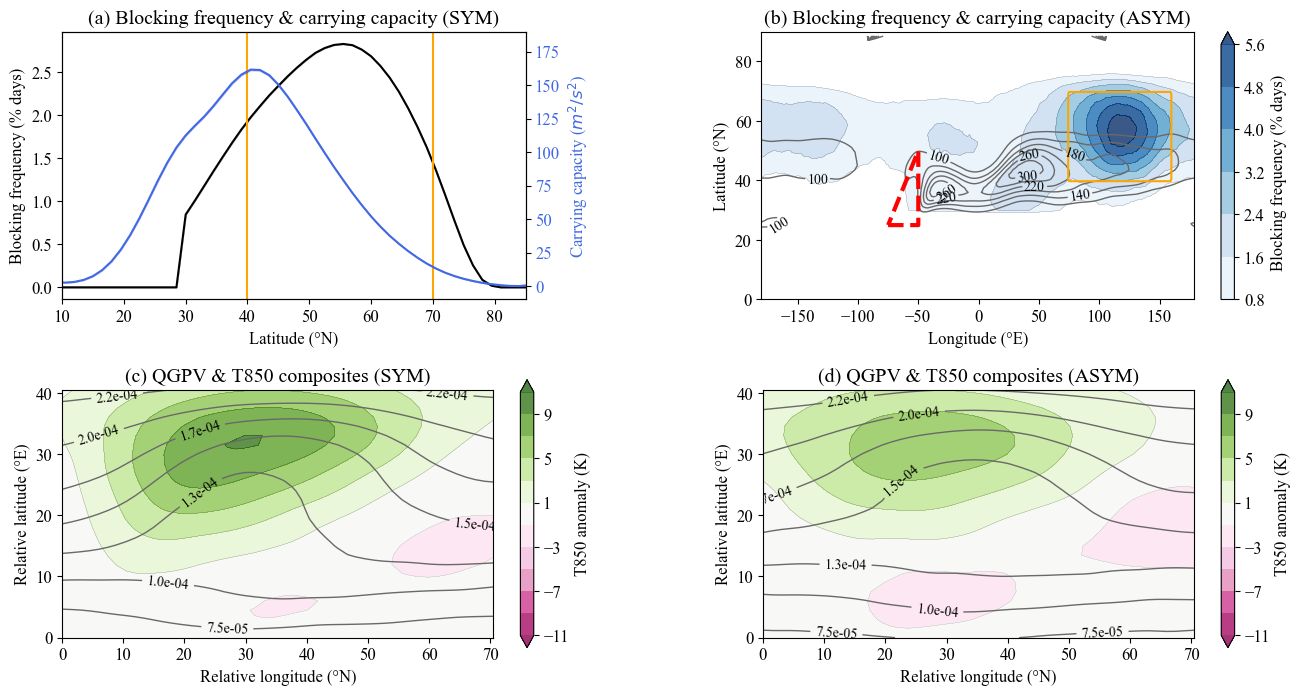

In [21]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12

# Triangle coordinates
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

fig = plt.figure(figsize=(16, 8))

# Parent GridSpec: 2 rows, 1 column
outer_gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0.3)

# First row: custom width ratios
gs_top = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs[0], wspace=0.47, width_ratios=[0.9, 1.05])
ax1_left = fig.add_subplot(gs_top[0, 0])
ax1_right = fig.add_subplot(gs_top[0, 1])
ax1 = [ax1_left, ax1_right]

# Second row: default width
gs_bottom = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs[1], wspace=0.3)
ax2 = [fig.add_subplot(gs_bottom[0, i]) for i in range(2)]

# Top left: zonal mean plot with twinx
block_freq_0 = ds_clims[0]['block_freq']
FC_0 = ds_clims[0]['FC']
lat = block_freq_0['lat']
block_freq_0_zonal = np.mean(block_freq_0, axis=-1)
FC_0_zonal = np.mean(FC_0, axis=-1)

ax1_left_twin = ax1_left.twinx()
ax1_left.plot(lat, block_freq_0_zonal, color='black', label='Blocking Frequency')
ax1_left.set_ylabel('Blocking frequency (% days)', color='black')
ax1_left.tick_params(axis='y', labelcolor='black')
ax1_left.set_xlabel('Latitude (°N)')
ax1_left.set_title('(a) Blocking frequency & carrying capacity (SYM)')
ax1_left.axvline(x=40, color='orange', linestyle='-', linewidth=1.5)
ax1_left.axvline(x=70, color='orange', linestyle='-', linewidth=1.5)
ax1_left.set_xlim(10, 85)

ax1_left_twin.plot(lat, FC_0_zonal, color='royalblue', label='Carrying capacity')
ax1_left_twin.set_ylabel('Carrying capacity ($m^2/s^2$)', color='royalblue')
ax1_left_twin.tick_params(axis='y', labelcolor='royalblue')
ax1_left_twin.set_xlim(10, 85)
ax1_left_twin.set_ylim(-10,190)

# Compute zonal means of std
block_freq_std_zonal = np.mean(block_std[0], axis=-1)/(np.sqrt(365*100*120))
FC_std_zonal = np.mean(FC_std[0], axis=-1)/np.sqrt(120)

# Add shading for block_freq std
ax1_left.fill_between(
    lat,
    block_freq_0_zonal - block_freq_std_zonal,
    block_freq_0_zonal + block_freq_std_zonal,
    color='black',
    alpha=0.2,
    label='Blocking Frequency ±1 std'
)

# Add shading for FC std
ax1_left_twin.fill_between(
    lat,
    FC_0_zonal - FC_std_zonal,
    FC_0_zonal + FC_std_zonal,
    color='blue',
    alpha=0.2,
    label='Carrying Capacity ±1 std'
)

# Top right: 2D fields (no Cartopy)
mask_asymmetric = define_mask(40, 70, 75, 160)
block_freq_2 = ds_clims[2]['block_freq']
FC_2 = ds_clims[2]['FC']
FC_levels = np.arange(100, 400, 40)
block_levels = np.arange(0.8,6,0.8)

cf2 = ax1_right.contourf(block_freq_2['lon'], block_freq_2['lat'], block_freq_2, extend='max',levels = block_levels, alpha=0.8, cmap='Blues')
cont = ax1_right.contour(block_freq_2['lon'], block_freq_2['lat'], block_freq_2, levels = block_levels, colors='k', linewidths = 0.1)
cfc2 = ax1_right.contour(FC_2['lon'], FC_2['lat'], FC_2, FC_levels, colors='dimgray', linewidths=1)
cdc3 = ax1_right.contour(block_freq_2['lon'], block_freq_2['lat'], mask_asymmetric, levels=[0.5, 1.5], colors='orange', alpha=1)
ax1_right.plot(lons, lats, linestyle='--', linewidth=3, color='red')
ax1_right.clabel(cfc2, colors='k', fmt='%d', fontsize=10)
ax1_right.set_title('(b) Blocking frequency & carrying capacity (ASYM)')
fig.colorbar(cf2, ax=ax1_right, orientation='vertical', label='Blocking frequency (% days)')
ax1_right.set_xlabel('Longitude (°E)')
ax1_right.set_ylabel('Latitude (°N)')

# Second row: composites
exp_names = ['SYM', 'ASYM']
letters = ['(c)', '(d)']
t850_ano_levels = np.arange(-11, 12, 2)

for j,i in enumerate([0,2]):
    comp_qgpv = ds_composites[i]['composite_qgpv']
    comp_t850_ano = ds_composites[i]['composite_t850_ano']

    pcm = ax2[j].contourf(comp_t850_ano['lon'], comp_t850_ano['lat'], comp_t850_ano, t850_ano_levels, extend='both', alpha=0.8, cmap='PiYG')
    cont = ax2[j].contour(comp_t850_ano['lon'], comp_t850_ano['lat'], comp_t850_ano, t850_ano_levels, colors='k', linewidths = 0.1)
    fig.colorbar(pcm, ax=ax2[j], orientation='vertical', label='T850 anomaly (K)')

    cs = ax2[j].contour(comp_qgpv['lon'], comp_qgpv['lat'], comp_qgpv, colors='dimgray', linewidths=1)
    ax2[j].clabel(cs,colors='k', fmt='%.1e', fontsize=10)

    ax2[j].set_title(f'{letters[j]} QGPV & T850 composites ({exp_names[j]})')
    ax2[j].set_xlabel('Relative longitude (°N)')
    ax2[j].set_ylabel('Relative latitude (°E)')
    ax2[j].set_aspect(1)

plt.savefig('PLOTS/Figure3.png',dpi=250)